# Imports and Pre-processing

In [1]:
# Importing packages
import pandas as pd
import numpy as np
import missingno as msno
import matplotlib.pyplot as plt
import warnings
from sklearn.impute import KNNImputer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, mean_squared_error, silhouette_score, calinski_harabasz_score, davies_bouldin_score
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from imblearn.over_sampling import SMOTE
from sklearn.cluster import AgglomerativeClustering, KMeans, DBSCAN, AffinityPropagation
from sklearn.neighbors import NearestNeighbors
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA

In [2]:
# reading the dataset and dropping the column ID (since a dataframe has indices, ID's are not necessary)
df = pd.read_csv("breast_cancer_ds.csv") 
df = df.drop(["ID"],axis=1)
df.head(10)

,Diagnosis,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,...,radius3,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,NaN,0.1866,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,NaN
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,...,NaN,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678
5,M,12.45,15.70,82.57,477.1,0.12780,NaN,0.15780,0.08089,0.2087,...,15.47,23.75,103.40,741.6,NaN,0.5249,0.5355,NaN,0.3985,0.12440
6,M,18.25,19.98,119.60,1040.0,0.09463,0.10900,0.11270,NaN,0.1794,...,22.88,NaN,153.20,1606.0,0.1442,0.2576,0.3784,0.1932,0.3063,0.08368
7,M,13.71,20.83,NaN,577.9,0.11890,0.16450,0.09366,0.05985,0.2196,...,17.06,28.14,110.60,897.0,0.1654,0.3682,0.2678,0.1556,0.3196,0.11510
8,M,13.00,21.82,87.50,519.8,NaN,0.19320,0.18590,0.09353,0.2350,...,15.49,30.73,106.20,739.3,0.1703,0.5401,0.5390,0.2060,0.4378,0.10720
9,M,12.46,24.04,83.97,475.9,0.11860,0.23960,0.22730,0.08543,0.2030,...,15.09,40.68,97.65,NaN,0.1853,1.0580,1.1050,0.2210,0.4366,0.20750


In [3]:
# Statistics of the dataframe
df.describe()

,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,fractal_dimension1,...,radius3,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3
count,525.000000,543.000000,528.000000,526.000000,527.000000,532.000000,522.000000,533.000000,538.000000,545.000000,...,498.000000,510.000000,552.000000,540.000000,506.000000,544.000000,541.000000,539.000000,541.000000,512.000000
mean,14.126410,19.295028,92.381023,656.567871,0.096417,0.104056,0.087825,0.048398,0.181230,0.062805,...,16.250022,25.719020,107.876286,869.718704,0.131987,0.258145,0.276119,0.114597,0.289833,0.083669
std,3.501462,4.299841,24.723441,354.859047,0.014074,0.052686,0.077282,0.039039,0.027662,0.007107,...,4.838797,6.210535,33.836094,555.602023,0.022200,0.158326,0.209986,0.065294,0.061915,0.017806
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.081250,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.155000,75.135000,421.475000,0.086210,0.065175,0.029600,0.020170,0.161900,0.057690,...,13.035000,21.120000,84.402500,513.700000,0.116850,0.150175,0.116800,0.064530,0.250200,0.071412
50%,13.380000,18.890000,86.735000,548.750000,0.095940,0.092350,0.061680,0.032790,0.179200,0.061480,...,14.940000,25.405000,98.115000,677.600000,0.131200,0.216850,0.230200,0.100100,0.281500,0.079870
75%,15.780000,21.805000,106.225000,787.050000,0.105350,0.130325,0.127075,0.070380,0.195700,0.066120,...,18.707500,30.015000,126.950000,1037.250000,0.145900,0.341700,0.386100,0.161350,0.317900,0.092037
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.218400,1.058000,1.252000,0.290300,0.663800,0.207500


# Missingness

<Axes: >

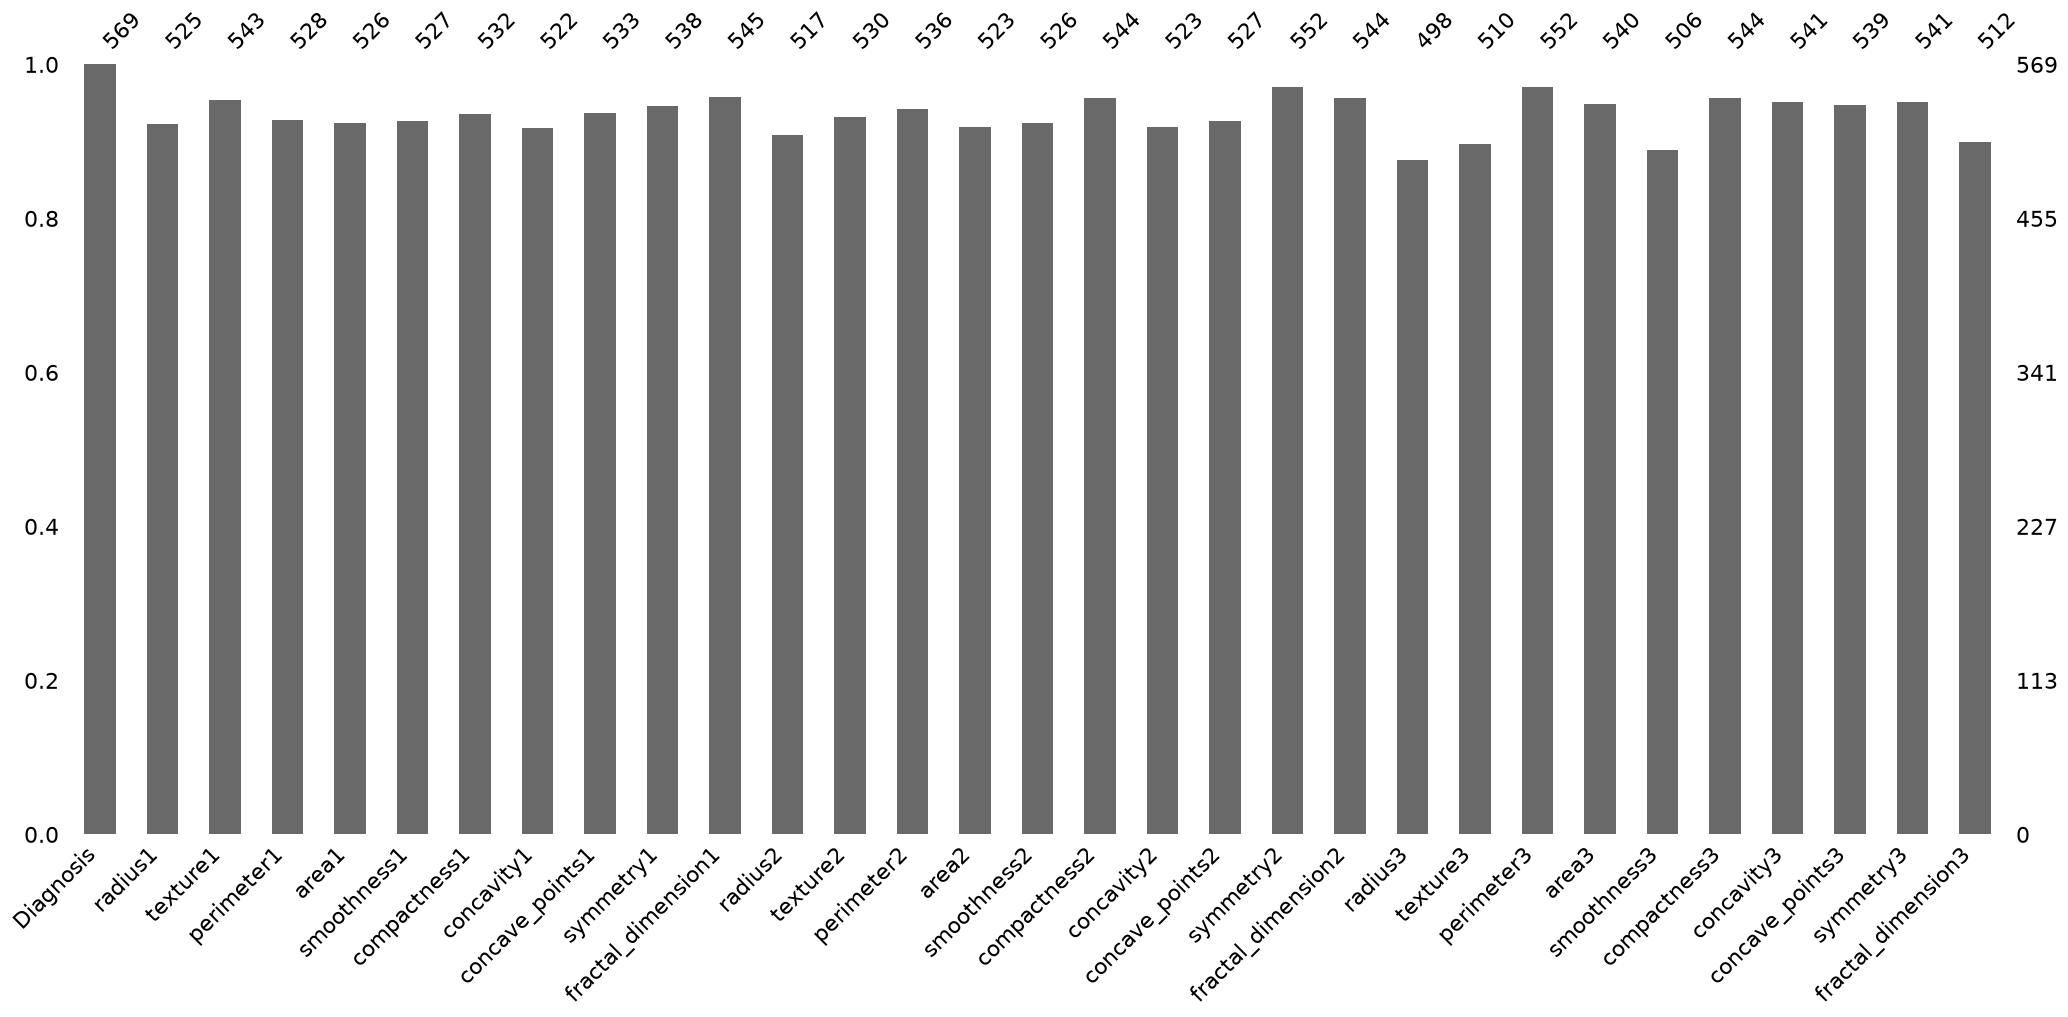

In [4]:
# Amount of missing values per column
msno.bar(df)

<Axes: >

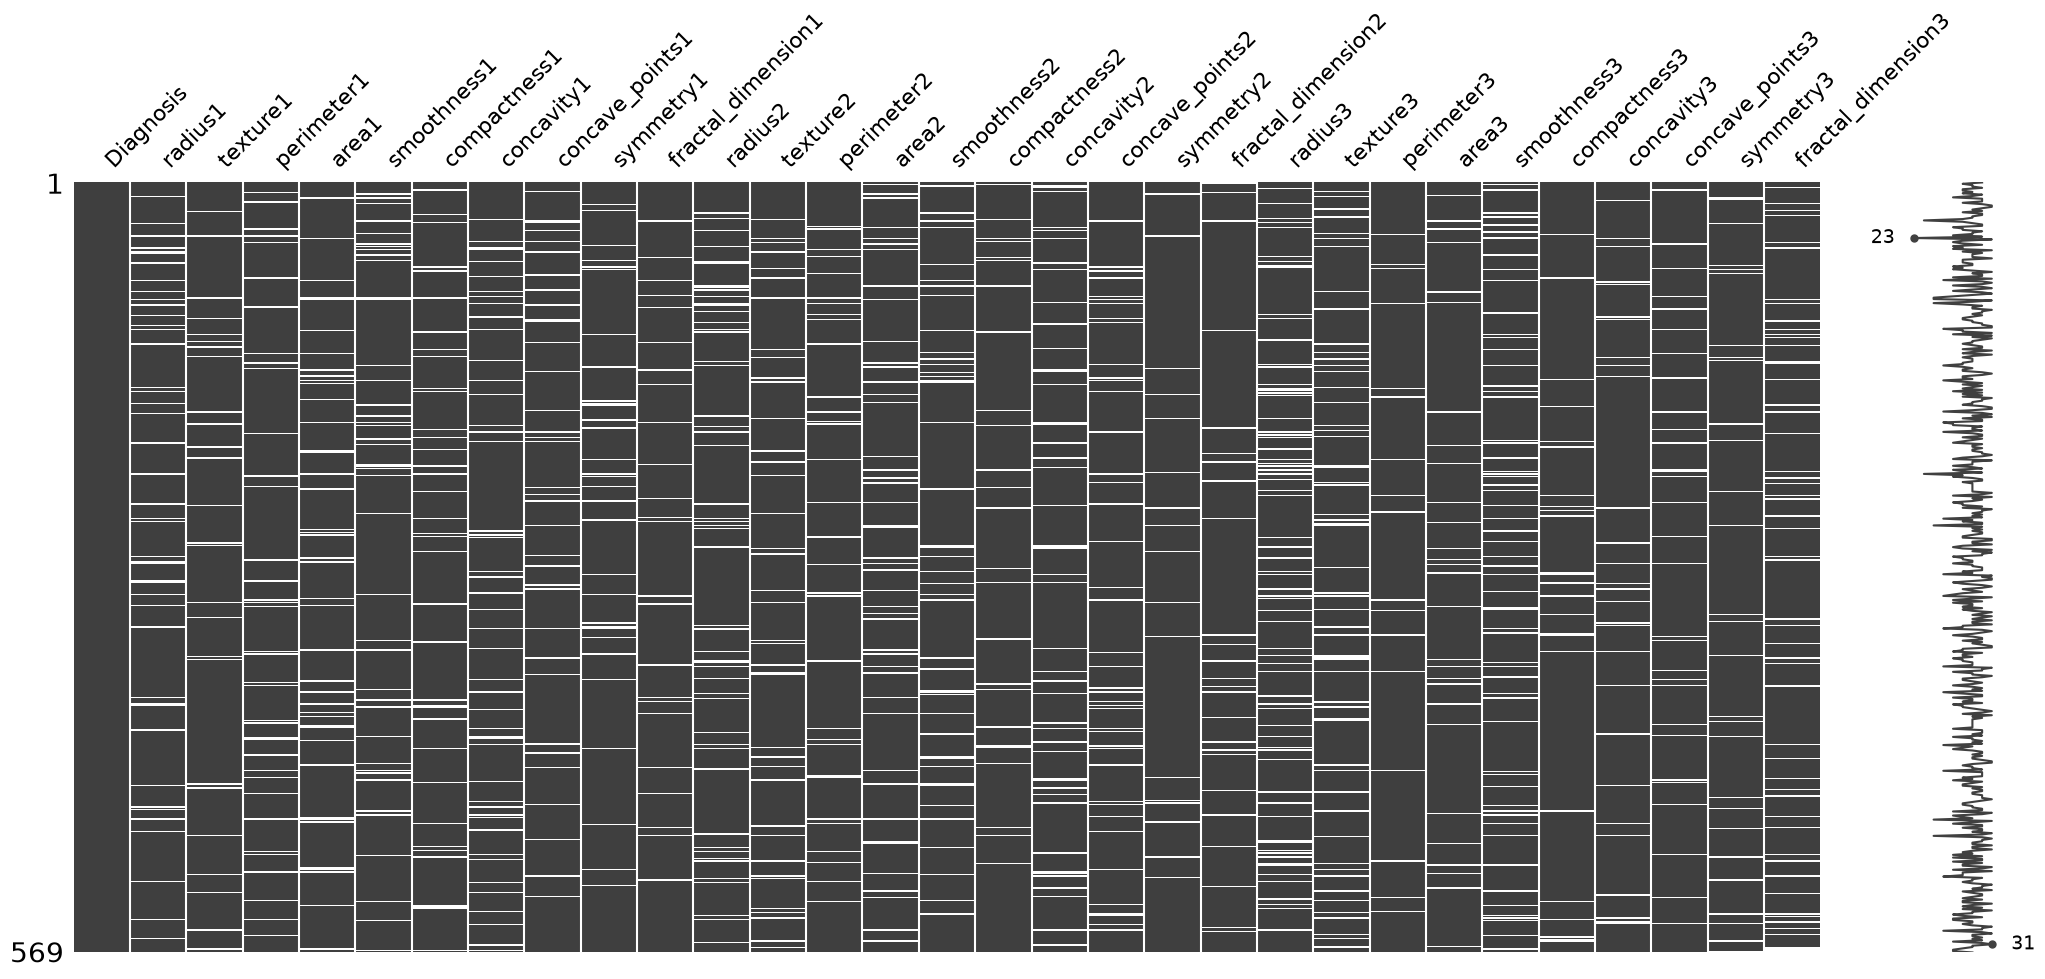

In [5]:
# Showing missingness per column
msno.matrix(df)

<Axes: >

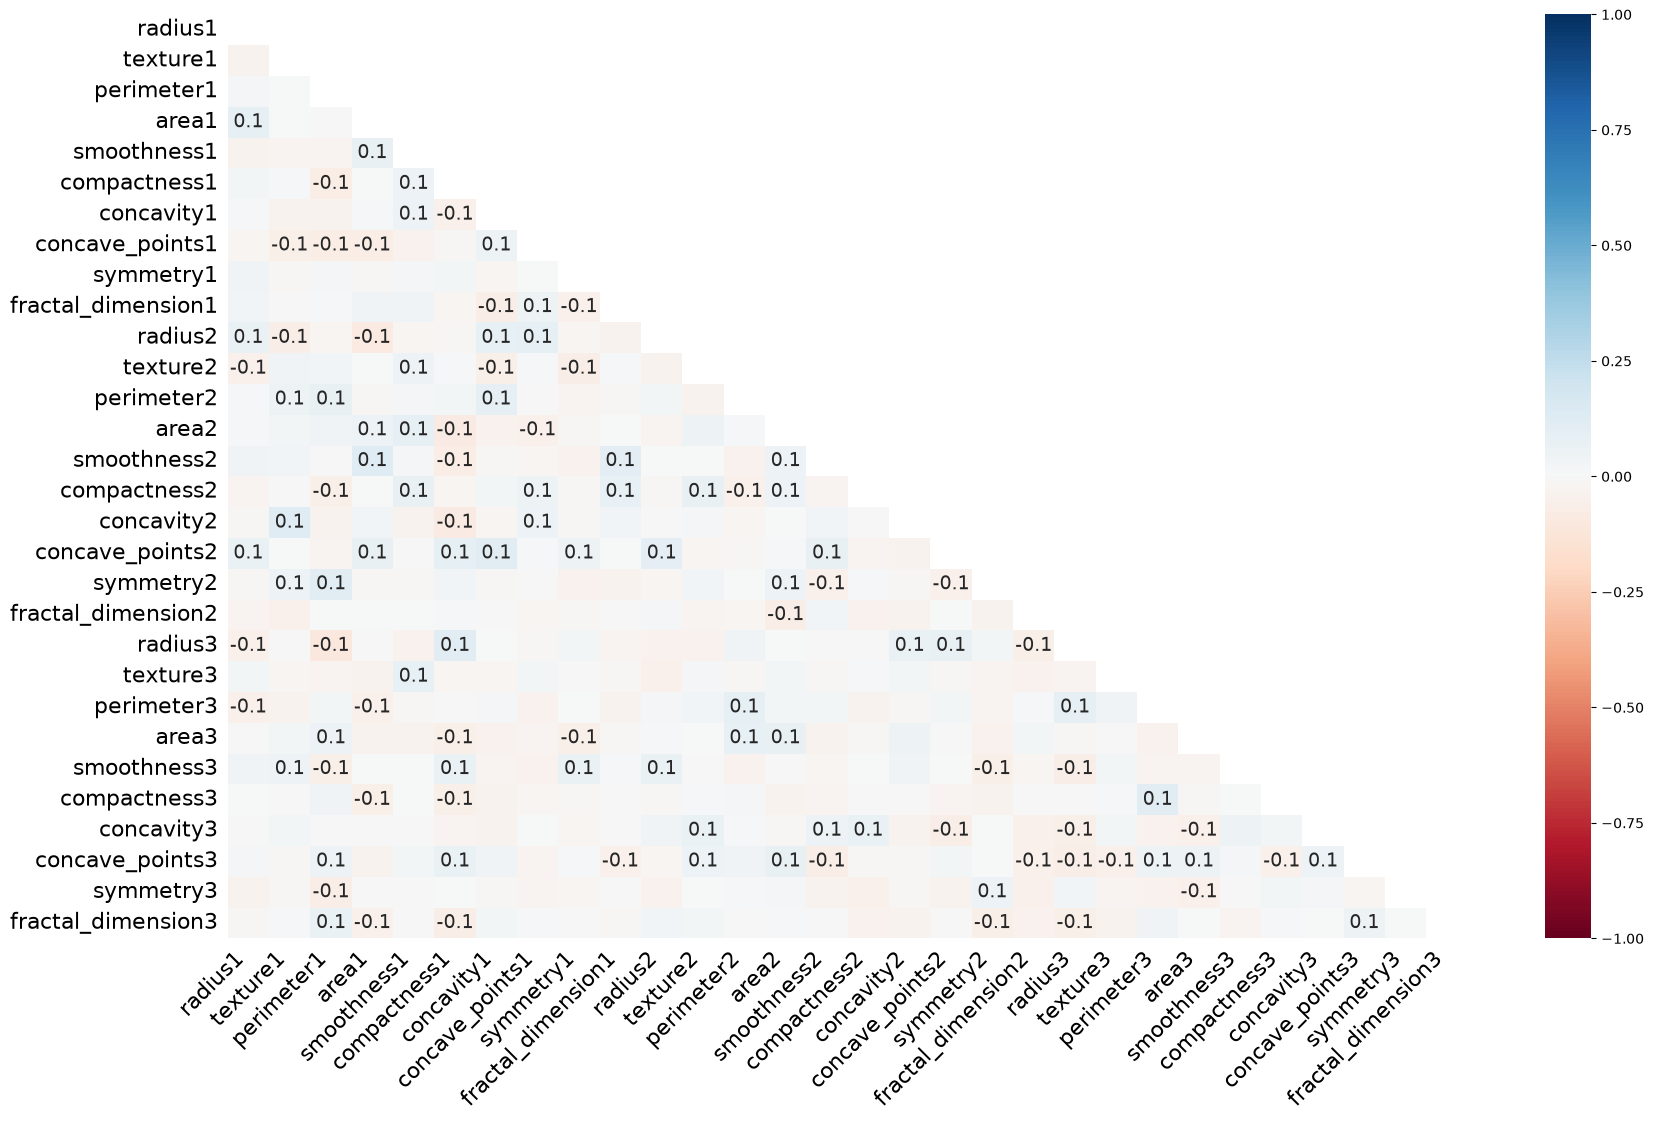

In [6]:
# Correlation of missingness between all features to determine type of missingness
msno.heatmap(df)

In [7]:
# Highest number of values missing in a row
print("Max missingness in a row: ", max(df.isna().sum(axis = 1)))

Max missingness in a row:  8


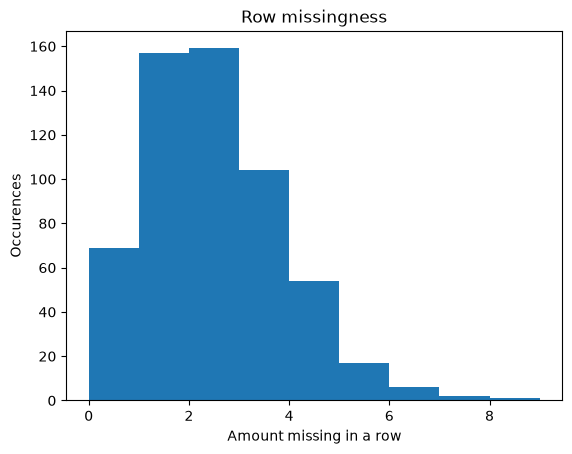

In [8]:
# histogram of number of values missing per row
plt.hist(df.isna().sum(axis = 1), bins = [0,1, 2, 3, 4,5,6,7,8,9])
plt.xlabel("Amount missing in a row")
plt.ylabel("Occurences")
plt.title("Row missingness")

plt.show()

In [9]:
# Count number of total missing values
print(df.isna().sum().sum())

1146


The missingness seems to be MCAR (Missing Completely At Random), which means that any imputation method can be used.

The row missingness is less than 50% for all entries, so there are no rows which needed to be removed.

# Imputation

In [10]:
# Train/test split
r_state = 0
X_train, X_test, y_train, y_test = train_test_split(df.drop(['Diagnosis'], axis=1), df['Diagnosis'], test_size=0.2, random_state= r_state, 
                                                    stratify=df['Diagnosis'])

# Hyperparameters chosen through a grid search
best_acc = 0
best_k = 0

# A for loop where for each neighbor n, imputation is done and then checked how well a machine learning method does
for n in range(1,21):
    imputer = KNNImputer(n_neighbors = n)
    filled = imputer.fit_transform(X_train)
    filled = pd.DataFrame(filled)

    model = RandomForestClassifier(random_state = r_state)
    model.fit(filled, y_train)

    second_test = imputer.fit_transform(X_test)
    second_test = pd.DataFrame(second_test)
    y_pred2 = model.predict(second_test)
    
    print("Test Accuracy (k =", n, ")", f":{accuracy_score(y_test, y_pred2):.4f}")

    if accuracy_score(y_test, y_pred2) >= best_acc:
        best_acc = accuracy_score(y_test, y_pred2)
        best_k = n

Test Accuracy (k = 1 ) :0.9474
Test Accuracy (k = 2 ) :0.9298
Test Accuracy (k = 3 ) :0.9474
Test Accuracy (k = 4 ) :0.9386
Test Accuracy (k = 5 ) :0.9298
Test Accuracy (k = 6 ) :0.9298
Test Accuracy (k = 7 ) :0.9298
Test Accuracy (k = 8 ) :0.9386
Test Accuracy (k = 9 ) :0.9298
Test Accuracy (k = 10 ) :0.9386
Test Accuracy (k = 11 ) :0.9474
Test Accuracy (k = 12 ) :0.9386
Test Accuracy (k = 13 ) :0.9386
Test Accuracy (k = 14 ) :0.9298
Test Accuracy (k = 15 ) :0.9386
Test Accuracy (k = 16 ) :0.9386
Test Accuracy (k = 17 ) :0.9386
Test Accuracy (k = 18 ) :0.9386
Test Accuracy (k = 19 ) :0.9386
Test Accuracy (k = 20 ) :0.9386


In [11]:
print("The k value with the highest accuracy is:", best_k)

The k value with the highest accuracy is: 11


In [12]:
# Impute the training and test sets separately to avoid data leakage
imputer = KNNImputer(n_neighbors = best_k)
X_train_imp = imputer.fit_transform(X_train)
X_train_imp = pd.DataFrame(X_train_imp)
X_train_imp.columns = df.drop(['Diagnosis'], axis=1).columns

X_test_imp = imputer.fit_transform(X_test)
X_test_imp = pd.DataFrame(X_test_imp)
X_test_imp.columns = df.drop(['Diagnosis'], axis=1).columns

<Axes: >

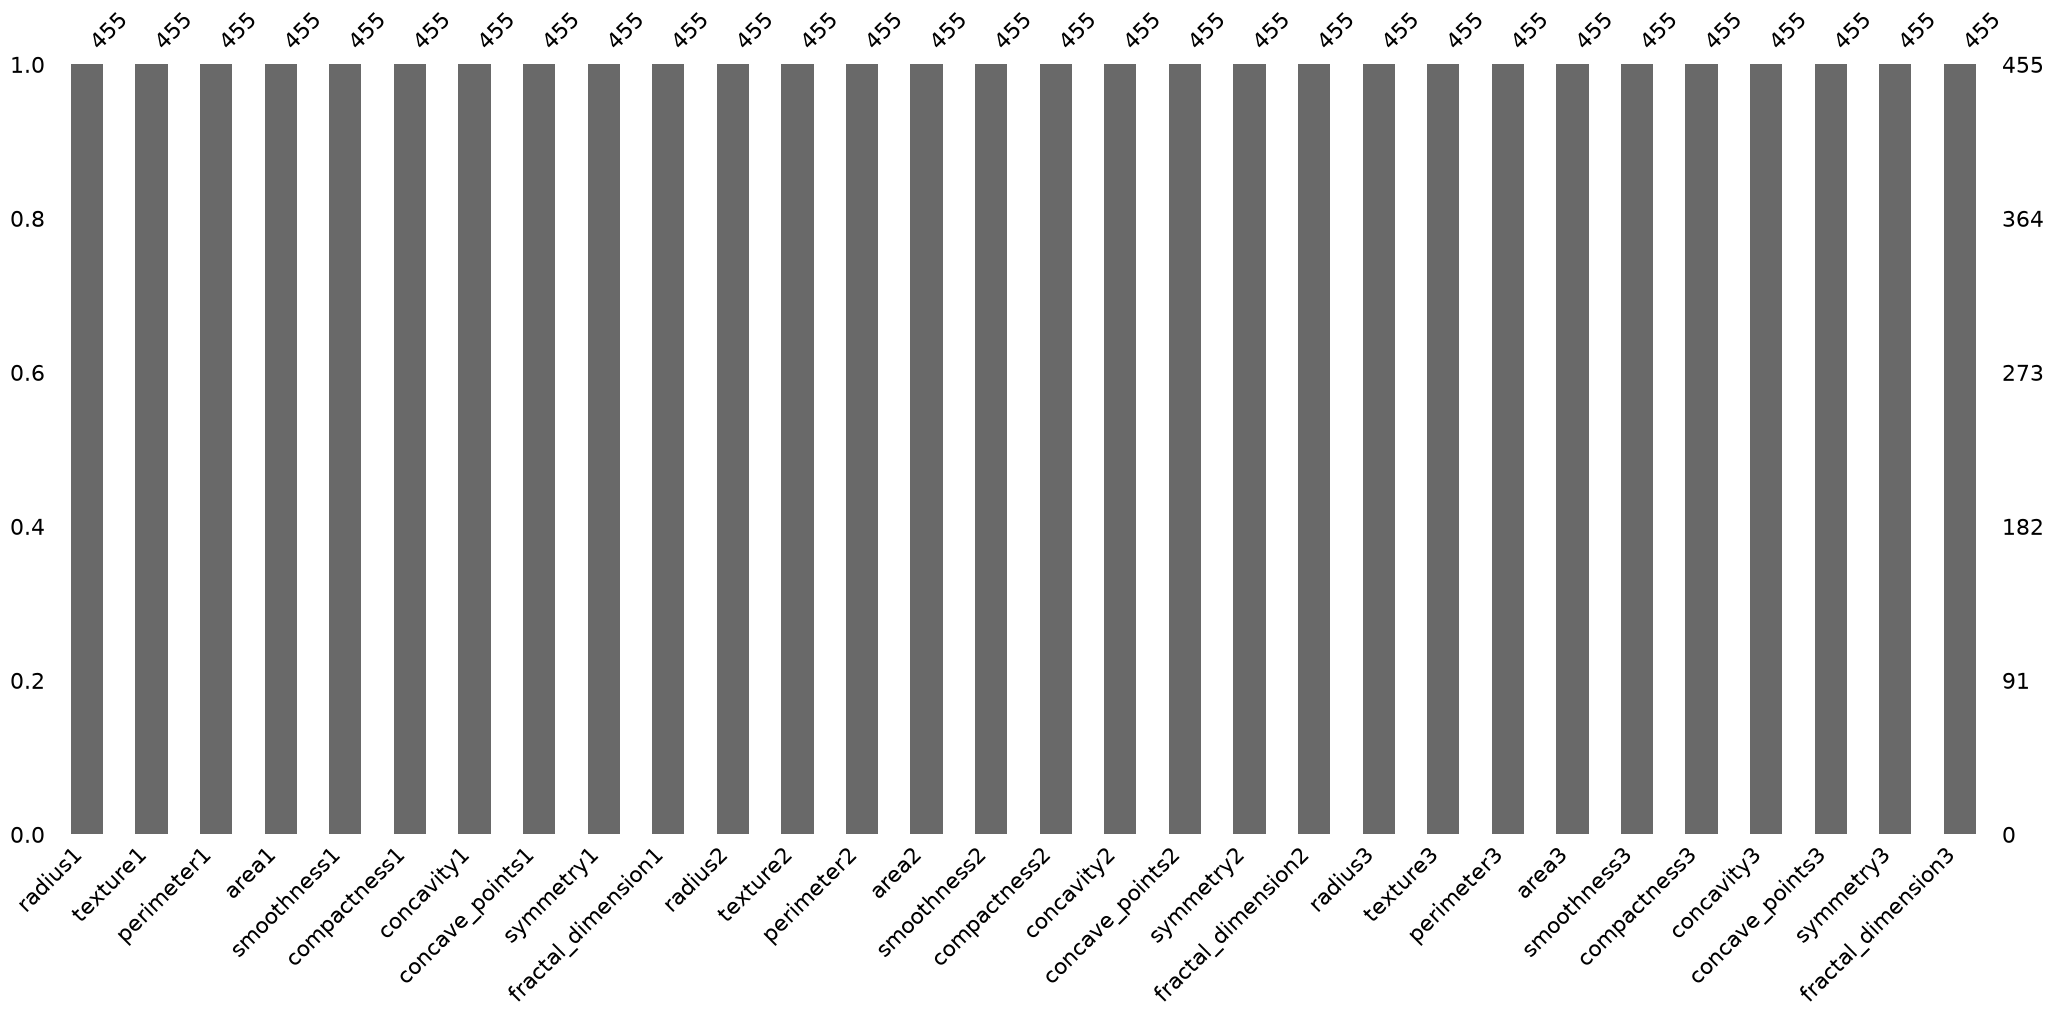

In [13]:
# Missingness in training data
msno.bar(X_train_imp)

<Axes: >

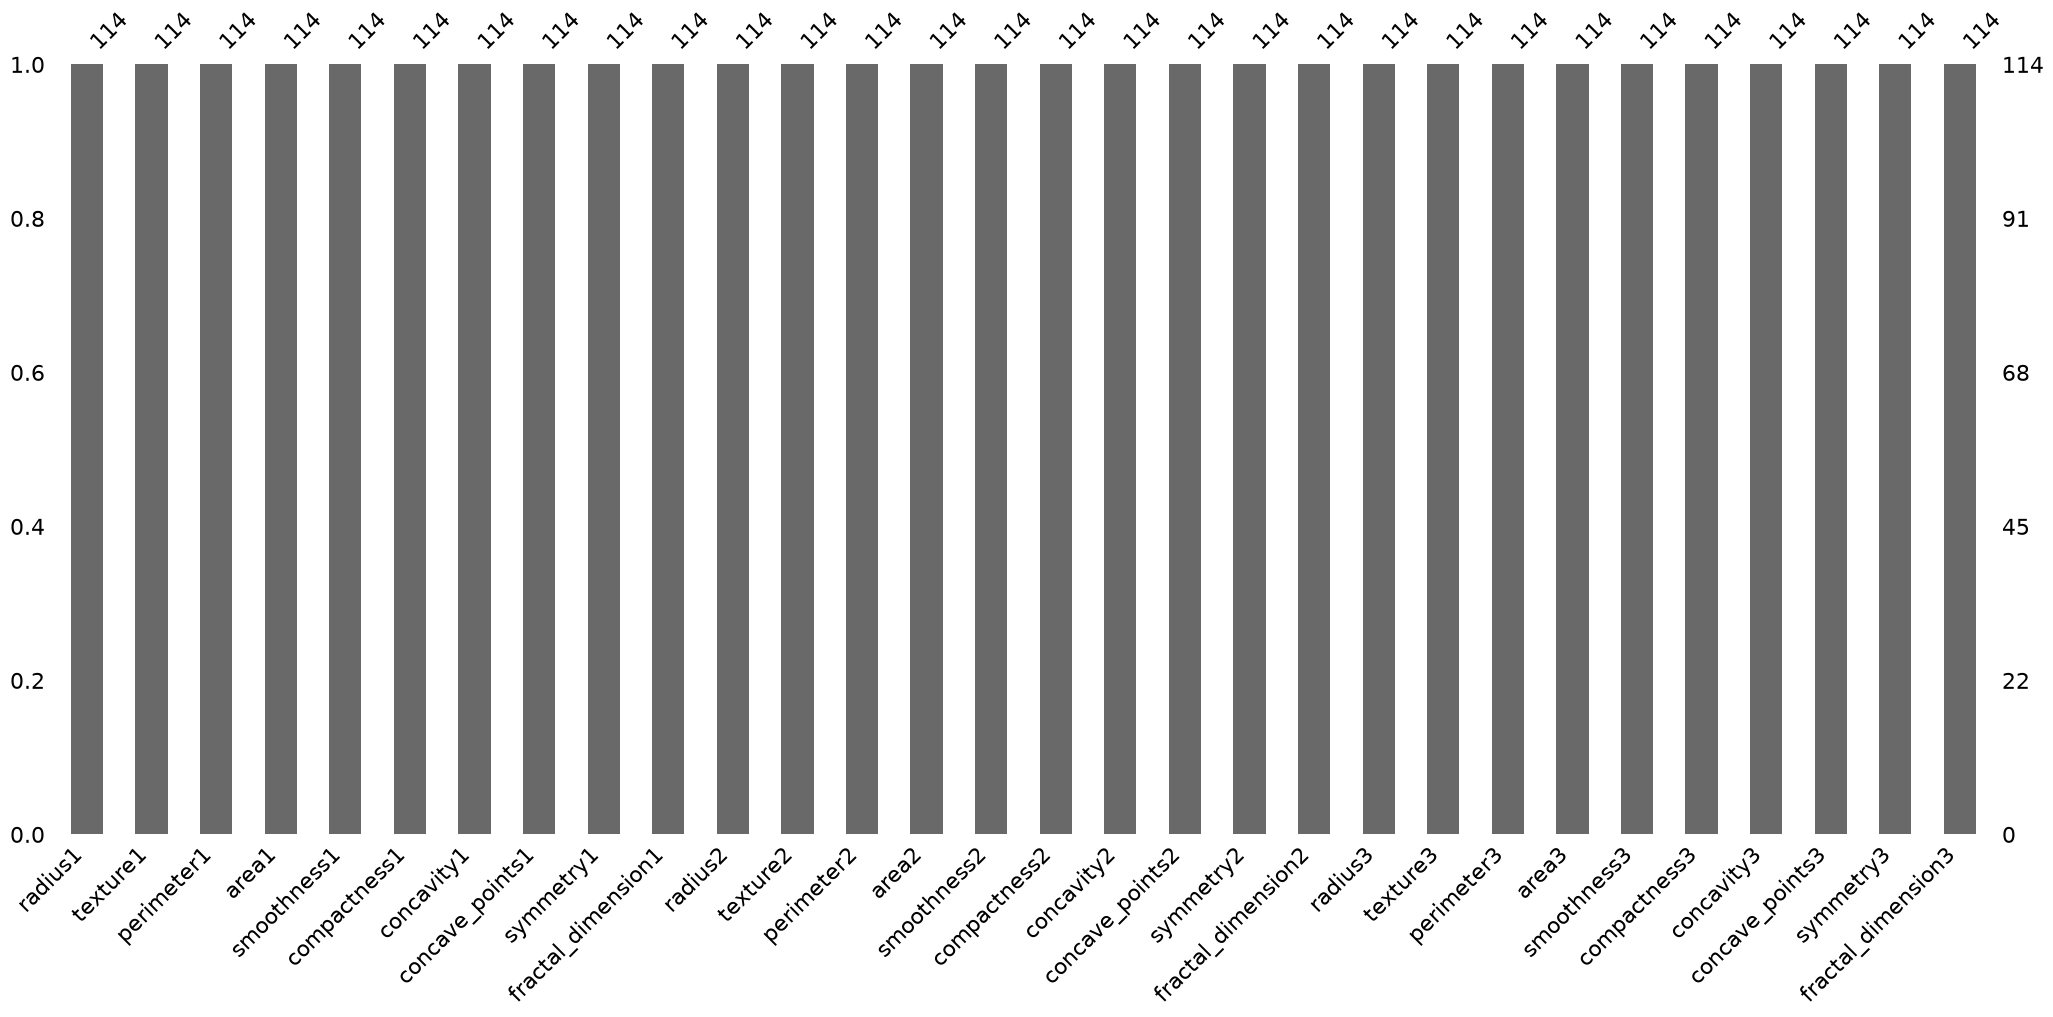

In [14]:
# Missingness in test data
msno.bar(X_test_imp)

# Oversampling

In [15]:
# Before rebalancing
print("Before:\n", y_train.value_counts())

Before:
 Diagnosis
B    285
M    170
Name: count, dtype: int64


In [16]:
# Using SMOTE for rebalancing
smote = SMOTE(sampling_strategy='minority', random_state = r_state)
X_train_sm, y_train_sm = smote.fit_resample(X_train_imp, y_train)

In [17]:
# After rebalancing
print("After:\n", y_train_sm.value_counts())

After:
 Diagnosis
B    285
M    285
Name: count, dtype: int64


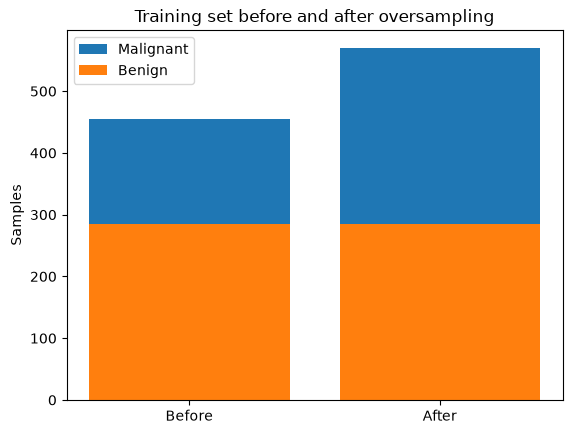

In [18]:
# Graph of values before and after oversampling
x = ['Before', 'After']
y1 = [y_train.value_counts().M, y_train.value_counts().B]
y2 = [y_train_sm.value_counts().M, y_train_sm.value_counts().B]

plt.bar(x, y1, bottom=y2)
plt.bar(x, y2)
plt.legend(["Malignant", "Benign"])
plt.title("Training set before and after oversampling")
plt.ylabel("Samples")
plt.show()

# Outliers (Isolation Forest)

In [19]:
# Training the model
iso_f = IsolationForest(random_state= r_state, contamination = 0.01)
iso_f.fit(X_train_imp)

,"contamination contamination: 'auto' or float, default='auto'The amount of contamination of the data set, i.e. the proportionof outliers in the data set. Used when fitting to define the thresholdon the scores of the samples.- If 'auto', the threshold is determined as in the original paper.- If float, the contamination should be in the range (0, 0.5]... versionchanged:: 0.22 The default value of ``contamination`` changed from 0.1 to ``'auto'``.",0.01
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo-randomness of the selection of the featureand split values for each branching step and each tree in the forest.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",0
,"n_estimators n_estimators: int, default=100The number of base estimators in the ensemble.",100
,"max_samples max_samples: ""auto"", int or float, default=""auto""The number of samples to draw from X to train each base estimator.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` samples.- If ""auto"", then `max_samples=min(256, n_samples)`.If max_samples is larger than the number of samples provided,all samples will be used for all trees (no sampling).",'auto'
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator.- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.Note: using a float number less than 1.0 or integer less than number offeatures will enable feature subsampling and leads to a longer runtime.",1.0
,"bootstrap bootstrap: bool, default=FalseIf True, individual trees are fit on random subsets of the trainingdata sampled with replacement. If False, sampling without replacementis performed.",False
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for :meth:`fit`. ``None`` means 1unless in a :obj:`joblib.parallel_backend` context. ``-1`` means usingall processors. See :term:`Glossary <n_jobs>` for more details.",None
,"verbose verbose: int, default=0Controls the verbosity of the tree building process.",0
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fit a wholenew forest. See :term:`the Glossary <warm_start>`... versionadded:: 0.21",False
Name,Type,Value
estimator_ estimator_: :class:`~sklearn.tree.ExtraTreeRegressor` instanceThe child estimator template used to create the collection offitted sub-estimators... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,ExtraTreeRegressor,ExtraTreeRegr...andom_state=0)


In [20]:
# Outlier scoring
df_anom = X_train_imp.loc[X_train_imp.index].copy()
df_anom['score'] = iso_f.decision_function(X_train_imp)
df_anom['outlier'] = iso_f.predict(X_train_imp)
df_anom['outlier'].value_counts()

outlier
 1    450
-1      5
Name: count, dtype: int64

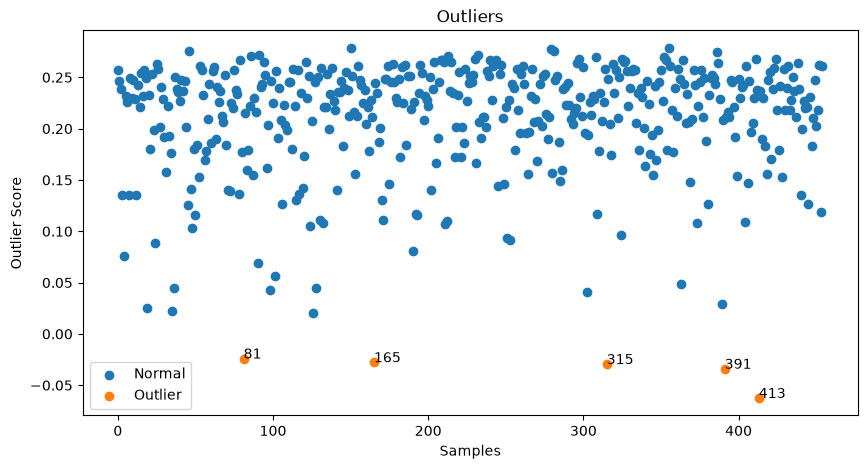

In [21]:
# Plotting the outliers
plt.figure(figsize=(10, 5))

normal = df_anom.loc[df_anom['outlier'] == 1]
outliers = df_anom.loc[df_anom['outlier'] == -1]

plt.scatter(normal.index, normal['score'], label='Normal')
plt.scatter(outliers.index, outliers['score'], label='Outlier')

# Adding a label to the outliers
i = 0
for outlier in outliers.index:
    plt.annotate(outlier, (outlier, outliers.iloc[i,30]))
    i += 1

plt.xlabel("Samples")
plt.ylabel("Outlier Score")
plt.title("Outliers")
plt.legend()
plt.show()

When removing the outliers, even trying different values for the contamination parameter, the accuracy of the classification went down. I therefore chose to not remove any outliers flagged by the isolated forest algorithm.

# Outliers (Principal Component Analysis)

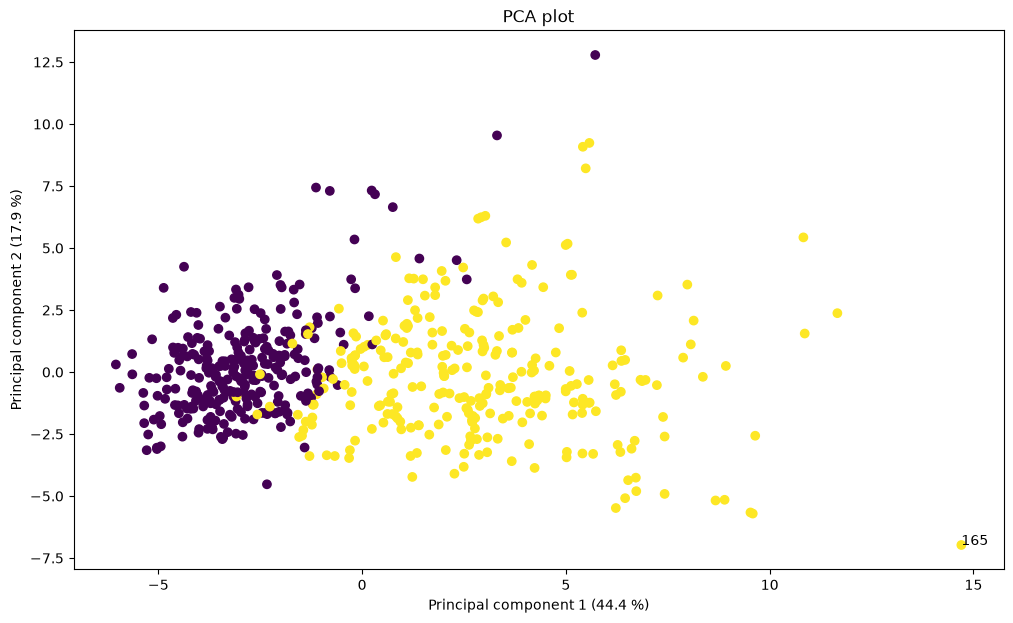

In [22]:
# Scaling the data
sc = StandardScaler()
X_train_pca = sc.fit_transform(X_train_sm)
X_test_pca = sc.transform(X_test_imp)

# Fitting the method 
pca = PCA()
pca.fit(X_train_pca)
X_train_pca = pd.DataFrame(pca.transform(X_train_pca))

# Plotting
encoder = LabelEncoder()
enc = encoder.fit_transform(y_train_sm)

x = X_train_pca.iloc[:,0]
y = X_train_pca.iloc[:,1]

fig = plt.figure(figsize=(12,7))
plt.scatter(x, y, c = enc)
plt.title('PCA plot')
plt.xlabel(f'Principal component 1 ({pca.explained_variance_ratio_[0]*100:.1f} %)')
plt.ylabel(f'Principal component 2 ({pca.explained_variance_ratio_[1]*100:.1f} %)')

# After plotting, there seems to be one outlier. In the plot it is labeled with its index
outliers = [165]
plt.annotate(text = str(outliers[0]), xy=(X_train_pca.iloc[outliers[0],0], X_train_pca.iloc[outliers[0],1]))
plt.show()

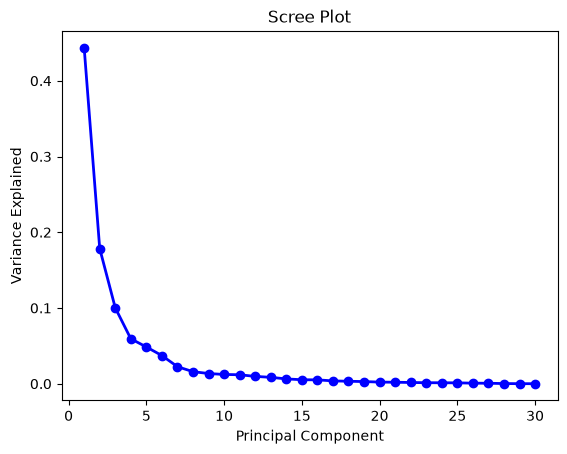

In [23]:
# Scree plot
PC_values = np.arange(pca.n_components_) + 1
plt.plot(PC_values, pca.explained_variance_ratio_, 'o-', linewidth=2, color='blue')
plt.title('Scree Plot')
plt.xlabel('Principal Component')
plt.ylabel('Variance Explained')
plt.show()

I initially removed the outlier labeled in the PCA plot. However, this made the feature importance perform slightly worse. Therefore, I chose to keep all samples of the dataset.

# Feature importance

In [24]:
# Train random forest
model = RandomForestClassifier(random_state = r_state)
model.fit(X_train_sm, y_train_sm)
importances = model.feature_importances_

# Scoring the model
acc = model.score(X_test_imp, y_test)
y_pred = model.predict(X_test_imp)
# print(classification_report(y_test, y_pred))
prev_pred = y_pred

In [25]:
# Get feature importances
feature_importances = pd.Series(importances, index=X_train_sm.columns)
features = pd.DataFrame(feature_importances.sort_values(ascending=False))

In [26]:
high_acc = 0
num_feat = 0
best_pred = []

for i in range(1,20):
    # Create dataframe with only top features
    top_features = features.head(i)
    row_names_feat = top_features.index
    df_feat = df.loc[:, row_names_feat] 

    # Train/test split
    X_train, X_test, y_train, y_test = train_test_split(df_feat, df['Diagnosis'], test_size=0.2, random_state=r_state, stratify=df['Diagnosis'])

    # Imputation on train and test set
    imputer = KNNImputer(n_neighbors = best_k)
    X_train_imp = imputer.fit_transform(X_train)
    X_train_imp = pd.DataFrame(X_train_imp)
    X_train_imp.columns = df_feat.columns
    
    X_test_imp = imputer.fit_transform(X_test)
    X_test_imp = pd.DataFrame(X_test_imp)
    X_test_imp.columns = df_feat.columns
    
    # Oversampling
    X_train_sm, y_train_sm = smote.fit_resample(X_train_imp, y_train)

    # Training the model
    model = RandomForestClassifier(random_state = r_state)
    model.fit(X_train_sm, y_train_sm)
    
    # Scoring
    y_pred = model.predict(X_test_imp)
    acc2 = model.score(X_test_imp, y_test)

    # Keep the best accuracy
    if(acc2 > high_acc):
        high_acc = acc2
        num_feat = i
        best_pred = y_pred

print("Best acc: ", f"{high_acc:.4f}")
print("Number of features: ", num_feat)

Best acc:  0.9561
Number of features:  15


In [27]:
# Compare accuracies
print("Before feature selection: ", f"{acc:.4f}")
print("After feature selection: ", f"{high_acc:.4f}")

Before feature selection:  0.9298
After feature selection:  0.9561


In [28]:
# Comparing before and after feature importance
print(classification_report(y_test, prev_pred))
print(classification_report(y_test, best_pred))

              precision    recall  f1-score   support

           B       0.97      0.92      0.94        72
           M       0.87      0.95      0.91        42

    accuracy                           0.93       114
   macro avg       0.92      0.93      0.93       114
weighted avg       0.93      0.93      0.93       114

              precision    recall  f1-score   support

           B       0.99      0.94      0.96        72
           M       0.91      0.98      0.94        42

    accuracy                           0.96       114
   macro avg       0.95      0.96      0.95       114
weighted avg       0.96      0.96      0.96       114



# Clustering

In [29]:
# Scaling the data
scaler = StandardScaler()
X  = imputer.fit_transform(df_feat)
X = pd.DataFrame(X)
X_scaled = scaler.fit_transform(X)

In [30]:
methods = ["silhouette", "calinski_harabasz", "davies_bouldin"]

In [31]:
# Method for trying different clustering methods and metrics
def clust(mode, metric, hier = "ward"):
    best_score = -1
    best_c = 0
    score = 0
    
    for c in range(2,21):
        # Modes
        match mode:
            case "hierarchical":
                model = AgglomerativeClustering(n_clusters=c, linkage= hier)
            case "kmeans":
                warnings.filterwarnings('ignore')
                model = KMeans(n_clusters = c)
            case "dbscan":
                ep = 0.3 + (0.1 * c) 
                model = DBSCAN(eps= ep)
            case "affinity":
                damp = 0.5 + (c - 2) * (0.5 / 19)
                model = AffinityPropagation(damping = damp, random_state= r_state)

        cluster_labels = model.fit_predict(X_scaled)
        n_clusters = len(set(cluster_labels)) - (1 if -1 in cluster_labels else 0)
        
        # Metrics
        if mode != "dbscan" or n_clusters > 1:
            match metric:
                case "silhouette":
                     score = silhouette_score(X_scaled, cluster_labels)
                case "calinski_harabasz":
                    score = calinski_harabasz_score(X_scaled, cluster_labels)
                case "davies_bouldin":
                    score = davies_bouldin_score(X_scaled, cluster_labels)

        # Getting the best score
        if score > best_score:
            best_score = score
            best_c = c

    # Printing results
    print("Best", metric, "score: ", f"{best_score:.4f}")
    if mode == "dbscan":
        best_c = len(set(cluster_labels)) - (1 if -1 in cluster_labels else 0)

    print("Number of clusters: ", best_c)

In [32]:
# Hierarchical clustering with ward linkage
print("Hierarchical clustering")
for met in methods:
    clust("hierarchical", met)
    print(" ")

Hierarchical clustering
Best silhouette score:  0.4259
Number of clusters:  2
 
Best calinski_harabasz score:  442.3493
Number of clusters:  2
 
Best davies_bouldin score:  1.7570
Number of clusters:  12
 


In [33]:
# Hierarchical clustering with complete linkage
print("Hierarchical clustering")
for met in methods:
    clust("hierarchical", met, "complete")
    print(" ")

Hierarchical clustering
Best silhouette score:  0.7076
Number of clusters:  2
 
Best calinski_harabasz score:  127.4292
Number of clusters:  8
 
Best davies_bouldin score:  1.3070
Number of clusters:  14
 


In [34]:
# Hierarchical clustering with average linkage
print("Hierarchical clustering")
for met in methods:
    clust("hierarchical", met, "average")
    print(" ")

Hierarchical clustering
Best silhouette score:  0.7076
Number of clusters:  2
 
Best calinski_harabasz score:  92.0486
Number of clusters:  9
 
Best davies_bouldin score:  0.9709
Number of clusters:  14
 


In [35]:
# Hierarchical clustering with single linkage
print("Hierarchical clustering")
for met in methods:
    clust("hierarchical", met, "single")
    print(" ")

Hierarchical clustering
Best silhouette score:  0.7304
Number of clusters:  2
 
Best calinski_harabasz score:  23.4418
Number of clusters:  2
 
Best davies_bouldin score:  0.4211
Number of clusters:  20
 


In [36]:
# Kmeans clustering
print("Kmeans clustering")
for met in methods:
    clust("kmeans", met)
    print(" ")

Kmeans clustering
Best silhouette score:  0.4467
Number of clusters:  2
 
Best calinski_harabasz score:  467.2018
Number of clusters:  2
 
Best davies_bouldin score:  1.7198
Number of clusters:  11
 


In [37]:
# DBSCAN
print("DBSCAN")
for met in methods:
    clust("dbscan", met)
    print(" ")

DBSCAN
Best silhouette score:  0.1574
Number of clusters:  1
 
Best calinski_harabasz score:  129.0010
Number of clusters:  1
 
Best davies_bouldin score:  3.5641
Number of clusters:  1
 


In [38]:
# Affinity clustering
print("Affinity clustering")
for met in methods:
    clust("affinity", met)
    print(" ")

Affinity clustering
Best silhouette score:  0.4510
Number of clusters:  20
 
Best calinski_harabasz score:  168.8199
Number of clusters:  20
 
Best davies_bouldin score:  1.5364
Number of clusters:  17
 


# Clustering with most important features

In [39]:
# Getting only data from top features
top_features = features.head(num_feat)
row_names_feat = top_features.index
df_feat = df.loc[:, row_names_feat] 

# Scaling the data
scaler = StandardScaler()
X  = imputer.fit_transform(df_feat)
X = pd.DataFrame(X)
X_scaled = scaler.fit_transform(X)

In [40]:
# Hierarchical clustering with ward linkage
print("Hierarchical clustering")
for met in methods:
    clust("hierarchical", met)
    print(" ")

Hierarchical clustering
Best silhouette score:  0.4339
Number of clusters:  2
 
Best calinski_harabasz score:  501.9616
Number of clusters:  2
 
Best davies_bouldin score:  1.6392
Number of clusters:  5
 


In [41]:
# Hierarchical clustering with complete linkage
print("Hierarchical clustering")
for met in methods:
    clust("hierarchical", met, "complete")
    print(" ")

Hierarchical clustering
Best silhouette score:  0.5050
Number of clusters:  2
 
Best calinski_harabasz score:  277.7167
Number of clusters:  4
 
Best davies_bouldin score:  1.2574
Number of clusters:  19
 


In [42]:
# Hierarchical clustering with average linkage
print("Hierarchical clustering")
for met in methods:
    clust("hierarchical", met, "average")
    print(" ")

Hierarchical clustering
Best silhouette score:  0.7038
Number of clusters:  2
 
Best calinski_harabasz score:  129.2344
Number of clusters:  6
 
Best davies_bouldin score:  0.8221
Number of clusters:  14
 


In [43]:
# Hierarchical clustering with single linkage
print("Hierarchical clustering")
for met in methods:
    clust("hierarchical", met, "single")
    print(" ")

Hierarchical clustering
Best silhouette score:  0.7427
Number of clusters:  2
 
Best calinski_harabasz score:  25.1913
Number of clusters:  2
 
Best davies_bouldin score:  0.4502
Number of clusters:  6
 


In [44]:
# Kmeans clustering
print("Kmeans clustering")
for met in methods:
    clust("kmeans", met)
    print(" ")

Kmeans clustering
Best silhouette score:  0.4850
Number of clusters:  2
 
Best calinski_harabasz score:  565.3530
Number of clusters:  2
 
Best davies_bouldin score:  1.4675
Number of clusters:  15
 


In [45]:
# DBSCAN
print("DBSCAN")
for met in methods:
    clust("dbscan", met)
    print(" ")

DBSCAN
Best silhouette score:  0.4091
Number of clusters:  1
 
Best calinski_harabasz score:  141.7599
Number of clusters:  1
 
Best davies_bouldin score:  2.5135
Number of clusters:  1
 


In [46]:
# Affinity clustering
print("Affinity clustering")
for met in methods:
    clust("affinity", met)
    print(" ")

Affinity clustering
Best silhouette score:  0.5443
Number of clusters:  19
 
Best calinski_harabasz score:  108.7820
Number of clusters:  5
 
Best davies_bouldin score:  1.2828
Number of clusters:  2
 


# Conclusions

Scores for the clustering (between brackets is the number of clusters): 
| Metric \ Method | Hierarchical (ward)  | Hierarchical (complete)  | Hierarchical (average)  | Hierarchical (single) | Kmeans | DBSCAN | Affinity |
| :-: | :-:  | :-:  | :-:  | :-:  |  :-:  | :-:  | :-:  |
| Silhouette | 0.4259 (2) | 0.7076 (2) | 0.7076 (2) | 0.7304 (2)|  0.4467 (2) | 0.1574 (1) | 0.4510 (20)|
| Calinski-Harabasz  | 442.3493 (2) | 127.4292 (8) |  92.0486 (9) | 23.4418 (2) |  467.2018 (2) | 129.0010 (1) | 168.89199 (20) |
| Davies-Bouldin  | 1.7570 (12) | 1.3070 (14)|  0.9709 (14) | 0.4211 (20) |  1.7198 (11) | 3.5641 (1) | 1.5364 (17)|

Scores for the clustering with important features (between brackets is the number of clusters):
| Metric \ Method | Hierarchical (ward)  | Hierarchical (complete)  | Hierarchical (average)  | Hierarchical (single) | Kmeans | DBSCAN | Affinity |
| :-: | :-:  | :-:  | :-:  | :-:  |  :-:  | :-:  | :-:  |
| Silhouette | 0.4339 (2)| 0.5050 (2)| 0.7038 (2) | 0.7427 (2)| 0.4850 (2) |0.4091 (1) | 0.5443 (19)) |
| Calinski-Harabasz  | 501.9616 (2) | 277.7167 (4) | 129.2344 (6)| 25.1913 (2) | 565.3530 (2) | 141.7599 (1)| 108.7820 (5)| 
| Davies-Bouldin  | 1.6392 (5) | 1.2574 (19)| 0.8221 (14)| 0.4502 (6) | 1.4675 (15)| 2.5135 (1)| 1.2828 (2) |

Removing outliers decreased the accuracy of the model. Therefore, I chose not to remove any samples in the rest of the code.

Feature selection did not have a big effect on the accuracy of the model. However, did slightly improve in all metrics (accuracy, precision, and recall).

For clustering, the ones using the smaller dataset which only kept important features worked better on almost every method and metric.
The hierarchical (average) performs the best for silhouette in both tables. For Calinski-Harabasz it's Kmeans. And for Davies-Bouldin it's DBSCAN.